# 01 · Exploratory analysis: IEEE-CIS e-commerce fraud

**Dataset.** Six months of online card payments from **Vesta**, a payment-guarantee
company, released for the 2019 IEEE Computational Intelligence Society Kaggle competition.
Unlike project 1, most features have *names and types*, which makes feature engineering
possible.

Two tables, joined on `TransactionID`:

| Group | Columns | Meaning (from Vesta's documentation) |
|---|---|---|
| Transaction | `TransactionDT`, `TransactionAmt`, `ProductCD` | time offset in seconds from an undisclosed start, amount in USD, product code |
| Card | `card1`–`card6` | card details: issuer, network (`card4`), type (`card6`)… masked as codes |
| Address | `addr1`, `addr2`, `dist1`, `dist2` | billing region and country, distances |
| E-mail | `P_emaildomain`, `R_emaildomain` | purchaser and recipient e-mail domains |
| Counts | `C1`–`C14` | counts such as how many addresses are linked to the card (meaning masked) |
| Time deltas | `D1`–`D15` | days since events such as the previous transaction |
| Matches | `M1`–`M9` | whether names, addresses… match (T/F) |
| Vesta features | `V1`–`V339` | ranks, counts and other engineered features |
| Identity | `id_01`–`id_38`, `DeviceType`, `DeviceInfo` | network and device fingerprinting, for ~24 % of transactions |

**How labels were made.** A transaction is fraud (`isFraud = 1`) if a chargeback was
reported on the card. Later transactions linked to the same user account, e-mail or
billing address are labelled fraud too. Anything with no report within 120 days is
legit. This means labels are partly a property of the **user**, not just the transaction.
That observation shapes notebook 02.

The competition's own test set has no labels, so we use only the labelled training file
and split it by time.

In [1]:
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from fraudkit import ieee
from fraudkit.data import load_ieee
from fraudkit.metrics import wilson_interval
from fraudkit.plotting import (
    CLASS_COLORS, DIVERGING, INK_2, MUTED, SERIES, class_hist, class_legend, finish, label_bars,
    set_style,
)

set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
# Adding columns to the wide frame triggers fragmentation warnings; defragmenting would
# mean a full 1 GB copy, which this 7 GB machine can't spare.
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

df = load_ieee()
df = ieee.add_time_features(df)
print(f"{len(df):,} transactions × {df.shape[1]} columns, {df.memory_usage(deep=True).sum() / 1e9:.2f} GB in memory")
print(f"fraud rate: {df.isFraud.mean():.2%}   time span: {df.day.max():.0f} days")

590,540 transactions × 437 columns, 0.98 GB in memory
fraud rate: 3.50%   time span: 183 days


Loading 650 MB of CSV with pandas' defaults would take ~2 GB (float64 numbers, Python
strings). `load_ieee` stores numbers as float32 and text as categoricals in a parquet
file, which halves memory and loads in seconds.

The fraud rate is **3.5 %**, twenty times project 1's. Still imbalanced, but with 20,000+
frauds the evaluation will be far less noisy.

## 1. Time: volume, fraud rate and our split

`TransactionDT` counts seconds from an unknown reference, so we work in days. The split
mirrors production: **train** on the first 4 months, **validate** on month 5, **test**
on month 6.

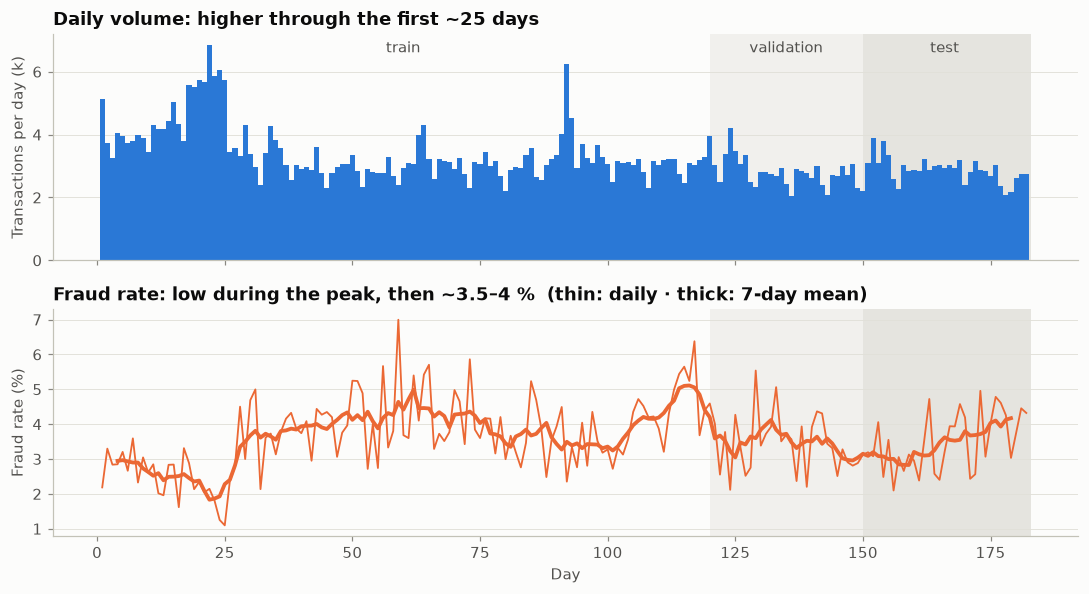

In [2]:
TRAIN_END, VAL_END = 120, 150
daily = df.groupby(df.day.astype(int)).isFraud.agg(n="size", frauds="sum")
daily["rate"] = daily.frauds / daily.n

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
ax1.bar(daily.index, daily.n / 1000, width=1, color=SERIES[0])
ax1.set_ylabel("Transactions per day (k)")
ax1.set_title("Daily volume: higher through the first ~25 days")
ax2.plot(daily.index, daily.rate * 100, color=CLASS_COLORS[1], lw=1.2)
ax2.plot(daily.index, daily.rate.rolling(7, center=True).mean() * 100, color=CLASS_COLORS[1], lw=2.5)
ax2.set_ylabel("Fraud rate (%)")
ax2.set_xlabel("Day")
ax2.set_title("Fraud rate: low during the peak, then ~3.5–4 %  (thin: daily · thick: 7-day mean)")
for ax in (ax1, ax2):
    for a, b, shade in [(TRAIN_END, VAL_END, "#e1e0d966"), (VAL_END, 183, "#c3c2b766")]:
        ax.axvspan(a, b, color=shade, lw=0, zorder=0)
    ax.grid(axis="x", visible=False)
for x, label in [(60, "train"), (135, "validation"), (166, "test")]:
    ax1.text(x, ax1.get_ylim()[1] * 0.92, label, ha="center", color=INK_2)
finish(fig)

**Reading it.** Volume is high for the first ~25 days. If the reference date is around
the start of December, as is often assumed for this dataset, that is the holiday
shopping season. Over the same days the fraud *rate* is lowest (~2–3 %): legit volume
grows faster than fraud. The rate then settles around 3.5–4 %, with a bump just before
the validation month. Seasonality like this is one reason to validate on later months rather than on
random rows.

In [3]:
split = np.select([df.day < TRAIN_END, df.day < VAL_END], ["train", "validation"], "test")
df["split"] = pd.Categorical(split, ["train", "validation", "test"])
df.groupby("split", observed=True).isFraud.agg(rows="size", frauds="sum", rate="mean")

,rows,frauds,rate
split,,,
train,410601,14419,0.035
validation,85303,2962,0.035
test,94636,3282,0.035


## 2. Missing values are everywhere, and they carry signal

columns with >50 % missing: 214 of 437


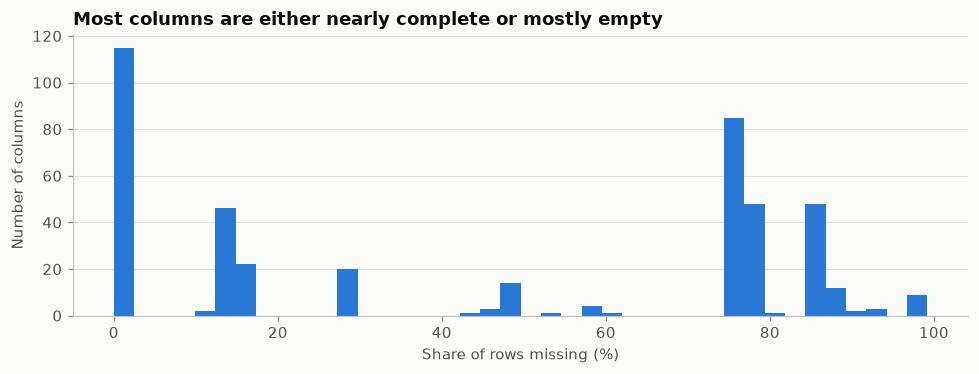

In [4]:
miss = df.isna().mean().drop("split").sort_values(ascending=False)   # no copy of the frame
print(f"columns with >50 % missing: {(miss > 0.5).sum()} of {len(miss)}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(miss * 100, bins=40, color=SERIES[0])
ax.set_xlabel("Share of rows missing (%)"); ax.set_ylabel("Number of columns")
ax.set_title("Most columns are either nearly complete or mostly empty")
ax.grid(axis="x", visible=False)
finish(fig)

Missingness here isn't random noise. Whole blocks of columns are missing together because
they come from the same source. The matrix below shows 300 random transactions (rows) by
all columns (in their original order). Dark cells are missing values.

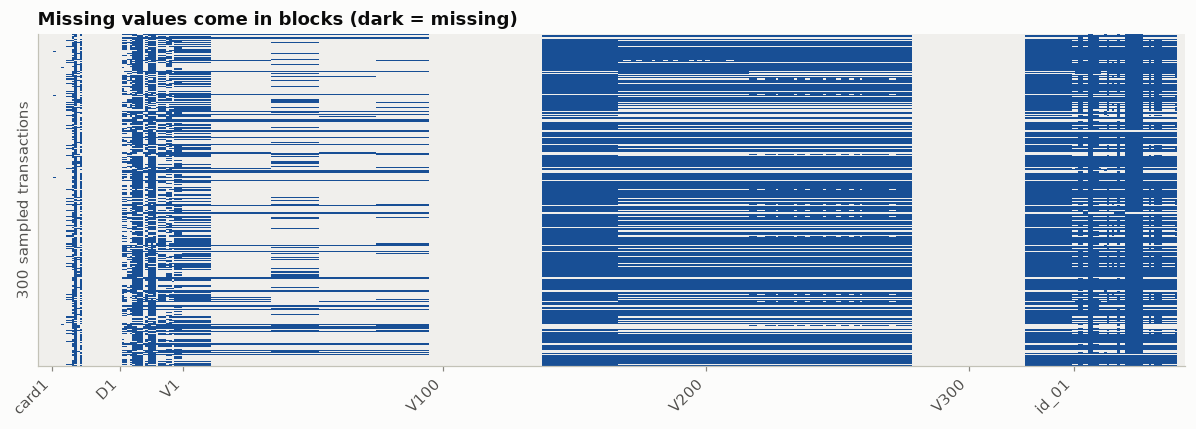

In [5]:
sample = df.sample(300, random_state=0).drop(columns=["split"])
fig, ax = plt.subplots(figsize=(11, 4))
ax.imshow(sample.isna().values, aspect="auto", cmap=plt.matplotlib.colors.ListedColormap(["#f0efec", "#184f95"]),
          interpolation="nearest")
ticks = [i for i, c in enumerate(sample.columns) if c in ("card1", "D1", "V1", "V100", "V200", "V300", "id_01")]
ax.set_xticks(ticks, [sample.columns[i] for i in ticks], rotation=45, ha="right")
ax.set_yticks([]); ax.grid(False)
ax.set_ylabel("300 sampled transactions")
ax.set_title("Missing values come in blocks (dark = missing)")
finish(fig)

In [6]:
has_identity = df.DeviceType.notna() | df.id_01.notna()
lo, hi = wilson_interval([df.isFraud[has_identity].sum(), df.isFraud[~has_identity].sum()],
                         [has_identity.sum(), (~has_identity).sum()])
pd.DataFrame({"share of rows": [has_identity.mean(), 1 - has_identity.mean()],
              "fraud rate": [df.isFraud[has_identity].mean(), df.isFraud[~has_identity].mean()],
              "95 % CI": [f"{lo[0]:.3f}–{hi[0]:.3f}", f"{lo[1]:.3f}–{hi[1]:.3f}"]},
             index=["identity data present", "identity data missing"])

,share of rows,fraud rate,95 % CI
identity data present,0.244,0.078,0.077–0.080
identity data missing,0.756,0.021,0.021–0.021


**Reading it.** Transactions with device/identity data are **almost 4× as likely** to be
fraud. The presence of the data says something about the channel (e.g. web checkouts
with device fingerprinting). For modelling this means:

* **Don't impute blindly.** Filling with a mean would erase the signal. Gradient-boosted
  trees handle missing values natively by learning which branch they should follow.
* For models that can't, add explicit "is missing" indicators.

## 3. Which categories are risky?

Fraud rate per category with a **95 % Wilson interval**. Raw rates for small categories
are unreliable. The Wilson interval is the standard confidence interval for a proportion,
and it behaves well even for small counts and rates near 0.

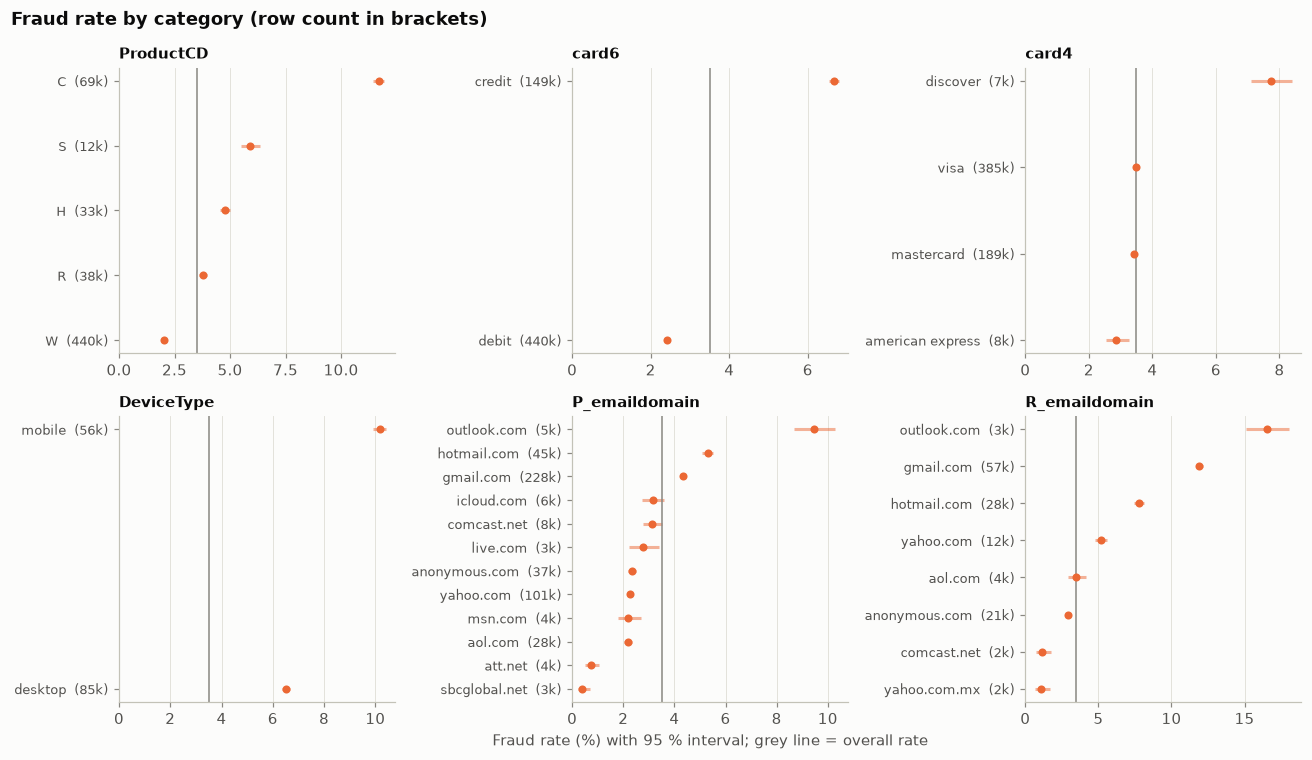

In [7]:
def rate_table(col, min_n=500, top=None):
    t = df.groupby(col, observed=True).isFraud.agg(n="size", frauds="sum")
    t = t[t.n >= min_n]
    if top:
        t = t.nlargest(top, "n")
    t["rate"] = t.frauds / t.n
    t["lo"], t["hi"] = wilson_interval(t.frauds, t.n)
    return t.sort_values("rate")


panels = [("ProductCD", None), ("card6", None), ("card4", None), ("DeviceType", None),
          ("P_emaildomain", 12), ("R_emaildomain", 8)]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
overall = df.isFraud.mean()
for ax, (col, top) in zip(axes.flat, panels):
    t = rate_table(col, top=top)
    y = np.arange(len(t))
    ax.hlines(y, t.lo * 100, t.hi * 100, color=SERIES[1], lw=2, alpha=0.5)
    ax.scatter(t.rate * 100, y, color=SERIES[1], s=28, zorder=3)
    ax.axvline(overall * 100, color=MUTED, lw=1)
    ax.set_yticks(y, [f"{i}  ({n / 1000:,.0f}k)" for i, n in zip(t.index, t.n)], fontsize=8.5)
    ax.set_title(col, fontsize=10)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(left=0)
axes[1, 1].set_xlabel("Fraud rate (%) with 95 % interval; grey line = overall rate")
fig.suptitle("Fraud rate by category (row count in brackets)", x=0.01, ha="left", fontweight="bold")
finish(fig)

**Reading it.**
* **Product C** has a fraud rate of ~12 %, six times product W (the bulk of the volume).
* **Credit cards** carry ~3× the risk of debit cards. **Discover** stands out among card networks.
* **Mobile** devices are riskier than desktop. Both are far riskier than the
  no-identity majority (see above).
* E-mail domains differ a lot: outlook.com purchasers are fraud ~4× as often as
  yahoo.com ones. The **recipient** domain (`R_emaildomain`, mostly filled for product C)
  spreads even wider, from ~1 % to ~17 %.

All these are useful but *coarse*. None separates fraud on its own the way V14 did in
project 1. The signal is spread across many weak features, which is exactly where
gradient boosting and feature engineering earn their keep.

## 4. Transaction amount

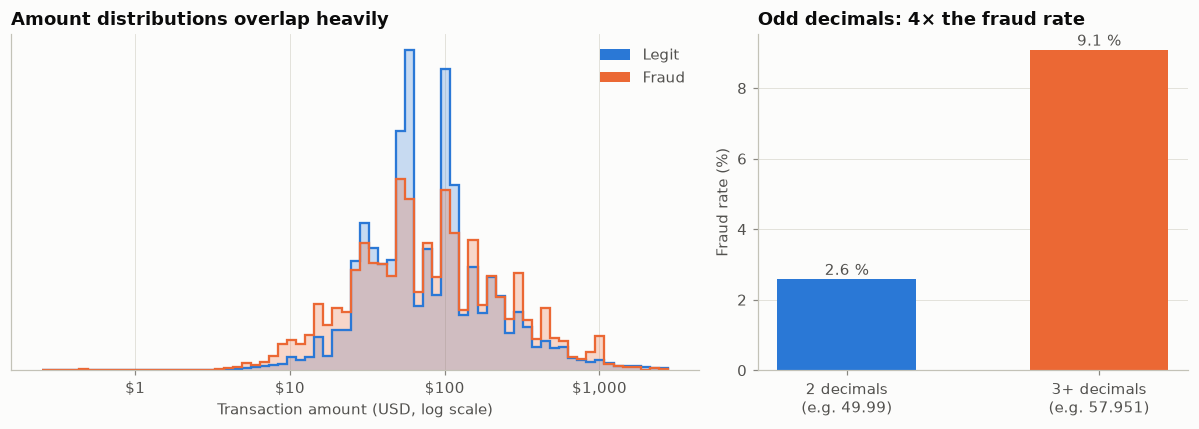

share of transactions with 3+ decimals: 14.2%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
v = np.log10(df.TransactionAmt.clip(lower=0.25))
class_hist(ax, v, df.isFraud, np.linspace(v.min(), v.quantile(0.999), 70))
ticks = [1, 10, 100, 1000]
ax.set_xticks(np.log10(ticks), [f"${t:,}" for t in ticks])
ax.set_xlabel("Transaction amount (USD, log scale)"); ax.set_yticks([])
ax.set_title("Amount distributions overlap heavily")
class_legend(ax, loc="upper right")

ax = axes[1]
df = ieee.add_amount_features(df)
t = df.groupby("amt_odd_decimals").isFraud.agg(n="size", frauds="sum")
t["rate"] = t.frauds / t.n
bars = ax.bar(["2 decimals\n(e.g. 49.99)", "3+ decimals\n(e.g. 57.951)"], t.rate * 100,
              color=[SERIES[0], SERIES[1]], width=0.55)
label_bars(ax, bars, fmt="{:.1f} %")
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Odd decimals: 4× the fraud rate")
ax.grid(axis="x", visible=False)
finish(fig)
print(f"share of transactions with 3+ decimals: {df.amt_odd_decimals.mean():.1%}")

**Reading it.** On its own the amount barely separates the classes. A small *derived*
feature does: about 14 % of amounts have more than two decimals, which suggests a
currency conversion (e.g. €49.99 charged as $57.951), i.e. a **foreign buyer**. Their
fraud rate is ~4× the rest. This is a first taste of feature engineering: domain
reasoning turns a raw number into a signal.

## 5. Redundancy: 339 V columns, far fewer ideas

Vesta's V columns come in families that share a missing-value pattern, and inside a
family many columns are near-copies. Below, the correlation matrix of one family.

339 V columns fall into 15 missing-value families


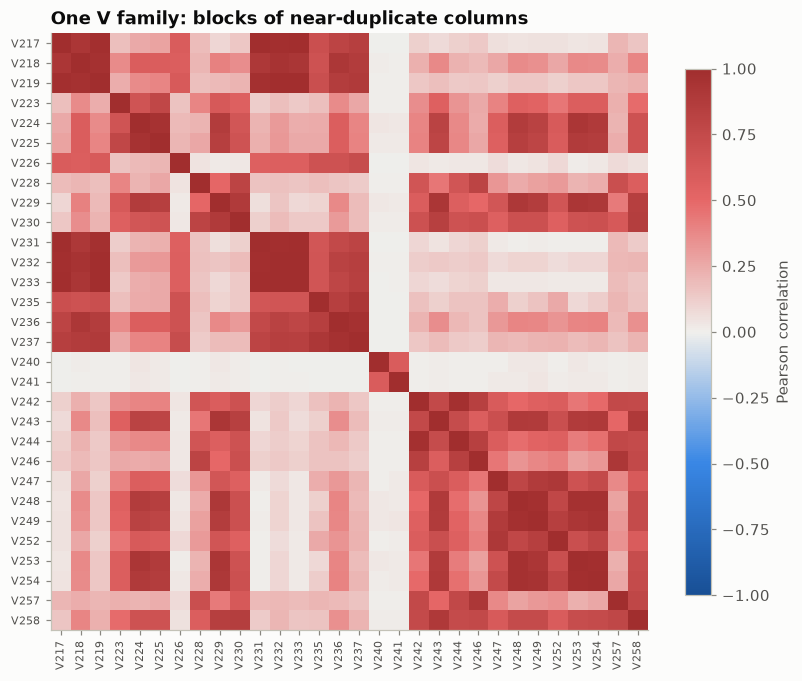

In [9]:
v_cols = [c for c in df if c.startswith("V") and c[1:].isdigit()]
nan_pattern = df[v_cols].isna().sum()
print(f"{len(v_cols)} V columns fall into {nan_pattern.nunique()} missing-value families")
family = nan_pattern[nan_pattern == nan_pattern.value_counts().index[0]].index[:30]
corr = df[family].sample(100_000, random_state=0).corr()

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(family)), family, rotation=90, fontsize=7)
ax.set_yticks(range(len(family)), family, fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("One V family: blocks of near-duplicate columns")
finish(fig)

In [10]:
keep_v = ieee.select_v_columns(df, threshold=0.75)
print(f"kept {len(keep_v)} of {len(v_cols)} V columns (|correlation| < 0.75 within each family)")

kept 130 of 339 V columns (|correlation| < 0.75 within each family)


`select_v_columns` keeps, within each family, a column only if it isn't strongly
correlated with one already kept. That removes 60 % of the V columns. Trees are fairly
robust to redundant inputs, but fewer columns mean faster training, less memory (this
machine has 7 GB of RAM) and cleaner explanations, because SHAP credit won't be split
across ten copies of one idea. Notebook 02 checks that the reduction costs no accuracy.

## 6. Drift: features that encode the calendar

A feature whose distribution moves steadily over time is dangerous. The model can learn
"values like this belong to the training months" and the pattern breaks on new data.
The `D` columns count days *since* an event, so for the same card they grow every day.
A popular fix for this dataset is to subtract them from the current day, turning "days
since the card was first seen" into "the day the card was first seen". Does it work?

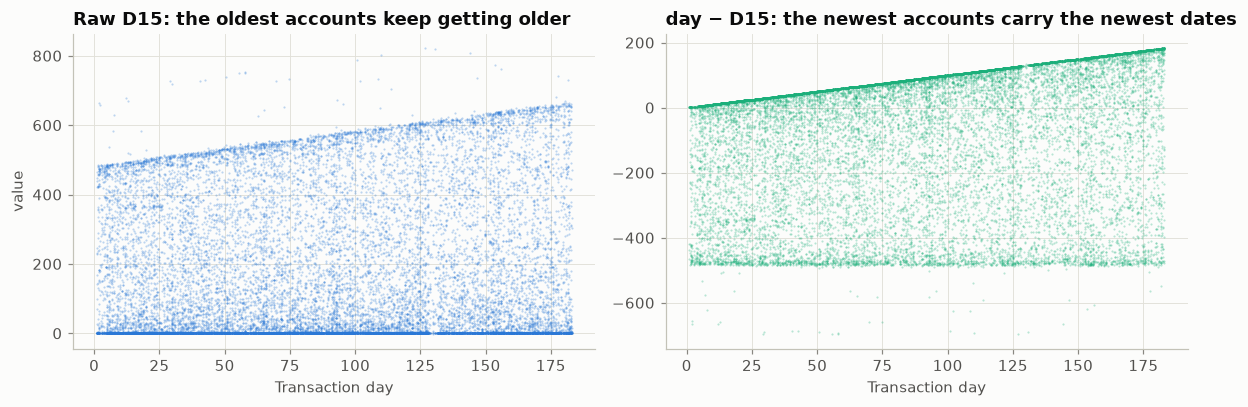

In [11]:
s = df[["day", "D15", "D1"]].dropna().sample(20_000, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
axes[0].scatter(s.day, s.D15, s=2, alpha=0.3, color=SERIES[0])
axes[0].set_title("Raw D15: the oldest accounts keep getting older"); axes[0].set_ylabel("value")
axes[1].scatter(s.day, np.floor(s.day) - s.D15, s=2, alpha=0.3, color=SERIES[2])
axes[1].set_title("day − D15: the newest accounts carry the newest dates")
for ax in axes:
    ax.set_xlabel("Transaction day")
finish(fig)

**Reading it.** Both versions drift, at opposite edges. Raw D15's *ceiling* rises
because the oldest accounts age a day every day. After the subtraction, each account's
value is fixed for life (the floor near −480 is flat), but the *ceiling* rises because
accounts opened recently carry recent dates. A date is a calendar feature by nature: an
account opened on day 170 can only appear in the test month.

### Adversarial validation: which features give away *when* a transaction happened?

**Adversarial validation** trains a classifier to tell training rows from test rows. If
it can, the two periods differ, and the most useful features for that task are the
drifting ones. An AUC near 0.5 means the periods look alike.

We run it twice: on the raw features, then after normalising the D columns. `TransactionID`
and `TransactionDT` are excluded because they are the calendar itself.

In [12]:
# Work on a 120k-row sample (60k per period) instead of copying the full 1 GB frame.
N_ADV = 60_000
adv = pd.concat([df[df.split == "train"].sample(N_ADV, random_state=0),
                 df[df.split == "test"].sample(N_ADV, random_state=0)])


def adversarial_auc(frame, features, seed=0):
    X = frame[features]
    y = (frame.split == "test").values.astype(int)
    idx = np.random.default_rng(seed).permutation(len(y))
    half = len(y) // 2
    m = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.1, num_leaves=31, verbose=-1, n_jobs=8)
    m.fit(X.iloc[idx[:half]], y[idx[:half]])
    auc = roc_auc_score(y[idx[half:]], m.predict_proba(X.iloc[idx[half:]])[:, 1])
    imp = pd.Series(m.booster_.feature_importance("gain"), index=features)
    return auc, imp / imp.sum()


exclude = {"TransactionID", "TransactionDT", "isFraud", "split", "day", "weekday", "hour"}
raw_feats = [c for c in adv.columns if c not in exclude]
auc_raw, imp_raw = adversarial_auc(adv, raw_feats)

adv = ieee.normalize_d_columns(adv)
norm_feats = [c for c in adv.columns if c not in exclude]
auc_norm, imp_norm = adversarial_auc(adv, norm_feats)
print(f"adversarial AUC, raw features:          {auc_raw:.3f}")
print(f"adversarial AUC, D columns normalised:  {auc_norm:.3f}")

adversarial AUC, raw features:          0.915
adversarial AUC, D columns normalised:  1.000


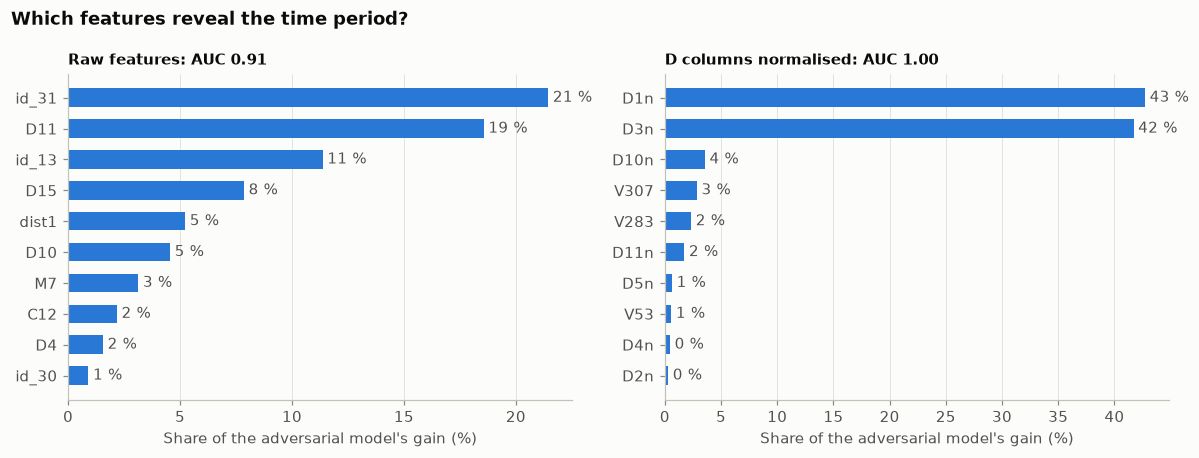

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (title, imp, auc) in zip(axes, [("Raw features", imp_raw, auc_raw),
                                        ("D columns normalised", imp_norm, auc_norm)]):
    top = imp.nlargest(10)[::-1]
    bars = ax.barh(top.index, top.values * 100, color=SERIES[0], height=0.6)
    label_bars(ax, bars, fmt="{:.0f} %", horizontal=True)
    ax.set_title(f"{title}: AUC {auc:.2f}", fontsize=10)
    ax.set_xlabel("Share of the adversarial model's gain (%)")
    ax.grid(axis="y", visible=False)
fig.suptitle("Which features reveal the time period?", x=0.01, ha="left", fontweight="bold")
finish(fig)

**Reading it.** The raw features already separate the periods well (AUC 0.91). The top
giveaways are `id_31` (browser version: new versions ship every few weeks), `id_13` and
the D columns. The "fix" makes things **worse**: AUC 1.00, with the normalised D1 and D3
doing almost all the work. `D3` counts days since the *previous* transaction, so
day − D3 is simply yesterday's date. D1 becomes the account's opening date, which
separates old and new accounts by period.

Lessons:
* **A transformation that "removes drift" by eye can add it.** Check with a test, not
  intuition. Adversarial validation takes a minute and catches it.
* **Normalised dates are still valuable as identifiers.** The account opening date is
  the key ingredient of the user ID in notebook 02, where it is used to *group*
  transactions, not as a feature for the model to split on.
* Whether raw or normalised D columns help the fraud model is a separate question. The
  only fair judge is performance on a later period, which notebook 02 measures.
* Some drift is irreducible: new browsers and devices appear every month. It is the
  reason models need retraining, which notebook 03 measures.

## 7. Takeaways for modelling

| Finding | Consequence |
|---|---|
| 3.5 % fraud, ~20k frauds, 6 months | Validate by time: train months 1–4, validation month 5, test month 6. Less noisy than project 1. |
| Labels propagate along users | Reconstruct a user ID and build user-history features (notebook 02). |
| Missing values come in blocks and carry signal | Keep them as missing; trees handle them natively. |
| Many weak categorical signals (product, card type, e-mail, device) | Gradient boosting with native categorical support. |
| Odd-decimal amounts → 4× fraud rate | Domain-driven amount features. |
| 339 V columns, mostly redundant | Keep ~130 representatives. |
| D columns and browser versions encode the calendar; normalising D makes it worse | Use the normalised D1 to build user IDs. Choose the D-feature variant by validation on a later month. |

**Next:** [02 · Feature engineering](02_feature_engineering.ipynb)